# Two-dimensional intensity self-imaging as a quantum measurement
**H. Hamam**

This benchmark prepares a single photon in a coherent superposition of nine orthogonal, forward-propagating modes on a transverse periodic cell. It asks whether a fixed quantum measurement gives the same absolute click distribution at two planes while the one-photon states differ under every transverse translation. The period, modal populations, and relative phase are design choices. A physical mask is not specified. The discrete periodic model represents ideal monochromatic modes.

## State preparation and propagation

Choose a normalized midpoint mode vector b, real and even under reversal of the transverse wavevector. The entrance state is prepared with coefficients $a_m=b_m e^{-i\beta_m s}$. The operation $|1_{\mathrm{in}}\rangle\mapsto\sum_m a_m |1_m\rangle$ is a one-input isometry because the modal weights sum to one. It can be extended to a unitary on the input mode space. This is a modal preparation target.

Starting from the free-photon Hamiltonian $H=\sum_{\mathbf k,\lambda}\hbar c|\mathbf k|a^\dagger_{\mathbf k,\lambda}a_{\mathbf k,\lambda}$, restrict to the forward monochromatic shell. A translation of the observation plane by $z$ multiplies the coefficient by $e^{i\beta_m z}$, where $\beta_m=\sqrt{k^2-|\mathbf q_m|^2}$. Here all nine channels propagate. The separation is $2s$. The free-field law uses photon momentum and dispersion directly and agrees with classical vacuum dispersion. No aperture boundary-value calculation enters this benchmark.

## Detector and recurrence criterion

Take one polarization per mode by projecting the laboratory y direction onto the plane perpendicular to its wavevector. The analyzer factor $g_m$ is the y component of the resulting unit polarization vector. An ideal coherent detection model resolves position while erasing direction. On a square cell of area $d^2$, its click density for a pure state is
$$p(\mathbf r)=\frac{\eta}{d^2}\left|\sum_m g_m a_m e^{i\mathbf q_m\cdot\mathbf r}\right|^2.$$
Each pixel effect is the integral of a positive rank-one density. The sum of the click effects is diagonal with entries $\eta|g_m|^2\le1$, so the complementary no-click effect is positive. The model assumes no angular discrimination beyond the analyzer and common gain. A real detector may have a different angular response. The gain $\eta=0.8$ is prescribed, not measured. The reported probability is per prepared photon.

Because b and g are real and even in transverse wavevector, the analyzed amplitudes at the two measurement planes are pointwise conjugates. Their intensities agree exactly in the mathematical model, so every pixel and the no-click event recur. The spectral phases are not all equal at the chosen separation. This is a two-plane result. A regular sequence of recurrences would impose more conditions.

## Distinguishing the quantum states

For any fractional transverse shift $(u,v)$, compute the squared one-photon overlap from the full nine-mode state. The sampled maximum is supplemented by a bound covering all shifts. Every shift lies within $1/(2N)$ per axis of a periodic grid point. The modulus of the overlap amplitude can rise from that sample by at most $(\pi/N)\sum_m |a_m|^2(|m_x|+|m_y|)$, by the triangle inequality and the bound on the change of a complex exponential. This gives an upper bound strictly below unity.

The equality of the pixel marginals is also accessible to classical first-order optics. The quantum formulation identifies the normalized one-photon state, detection effects and complement, and verifies non-equivalence under mode-sensitive measurements. Evanescent near fields and physical preparation of the prescribed spectrum are outside this benchmark.

In [1]:
import numpy as np
from itertools import product
from pathlib import Path
import json
import matplotlib.pyplot as plt

d = 1.7                              # period in each transverse direction, in wavelengths
k = 2*np.pi
orders = np.array(list(product(range(-1,2), repeat=2)))
q = k*orders/d
beta = np.sqrt(k*k - np.sum(q*q,axis=1))
# Transverse unit polarization obtained by projecting the laboratory y axis.
directions = np.column_stack((q,beta))/k
ey = np.array([0.,1.,0.])
transverse = ey - directions*directions[:,1,None]
polarization = transverse / np.linalg.norm(transverse,axis=1,keepdims=True)
analyzer = polarization @ ey
centre = np.flatnonzero(np.all(orders==0,axis=1))[0]
axial = np.flatnonzero(np.all(orders==[1,0],axis=1))[0]
half_separation = np.pi/(3*(beta[centre]-beta[axial]))
separation = 2*half_separation
# Choose a coherent real, inversion-symmetric state at the midpoint.
shell = np.sum(orders**2,axis=1)
midpoint = np.sqrt(np.array([.36,.40/4,.24/4])[shell])
psi0 = midpoint*np.exp(-1j*beta*half_separation)
psi1 = psi0*np.exp(1j*beta*separation)
efficiency = .80

def clicks(psi,n=64):
    """Integrate the pixel POVM exactly using the rectangular-pixel sinc factor."""
    x = (np.arange(n)+.5)*d/n
    dq = orders[:,None,:]-orders[None,:,:]
    pixel_integration = np.sinc(dq[:,:,0]/n)*np.sinc(dq[:,:,1]/n)
    e = np.exp(1j*np.outer(x,orders[:,0]*2*np.pi/d))
    f = np.exp(1j*np.outer(x,orders[:,1]*2*np.pi/d))
    a = psi*analyzer
    pm = efficiency*np.einsum('im,in,jm,jn,mn->ij',e,e.conj(),f,f.conj(),
                             a[:,None]*a.conj()[None,:]*pixel_integration,optimize=True).real/n**2
    miss = 1-pm.sum()
    return x,pm,float(miss)

def overlap_bound(n=1024):
    grid=np.arange(n)/n
    e=np.exp(2j*np.pi*np.outer(grid,orders[:,0]))
    f=np.exp(2j*np.pi*np.outer(grid,orders[:,1]))
    a=psi0.conj()*psi1
    sample=np.max(np.abs((e*a)@f.T))
    # Closest grid point is at most 1/(2n) away on each periodic axis.
    allowance=np.pi/n*np.dot(abs(a),np.abs(orders).sum(axis=1))
    return float(sample**2),float(min(1,(sample+allowance)**2))

x,p0,m0=clicks(psi0)
_,p1,m1=clicks(psi1)
sample,upper=overlap_bound()
assert np.isclose(np.vdot(psi0,psi0),1)
assert np.max(abs(psi1-psi0.conj())) < 1e-14
assert min(p0.min(),p1.min(),m0,m1)>=0
assert abs(p0.sum()-efficiency*np.dot(abs(psi0)**2,analyzer**2)) < 1e-13
assert upper<.999
results=dict(period_lambda=d,plane_separation_lambda=float(separation),
             click_probability=float(p0.sum()),no_click_probability=m0,
             total_variation=float((np.abs(p1-p0).sum()+abs(m1-m0))/2),
             sampled_max_squared_overlap=sample,certified_upper_squared_overlap=upper,
             axial_relative_phase_cycles=float((k-beta[axial])*separation/(2*np.pi)),
             diagonal_relative_phase_cycles=float((k-beta[-1])*separation/(2*np.pi)))
print(json.dumps(results,indent=2))

{
  "period_lambda": 1.7,
  "plane_separation_lambda": 1.7423712014758257,
  "click_probability": 0.6782006920415224,
  "no_click_probability": 0.32179930795847755,
  "total_variation": 1.2115281651167709e-16,
  "sampled_max_squared_overlap": 0.698170029261983,
  "certified_upper_squared_overlap": 0.7026890490763839,
  "axial_relative_phase_cycles": 0.3333333333333333,
  "diagonal_relative_phase_cycles": 0.775459610901606
}


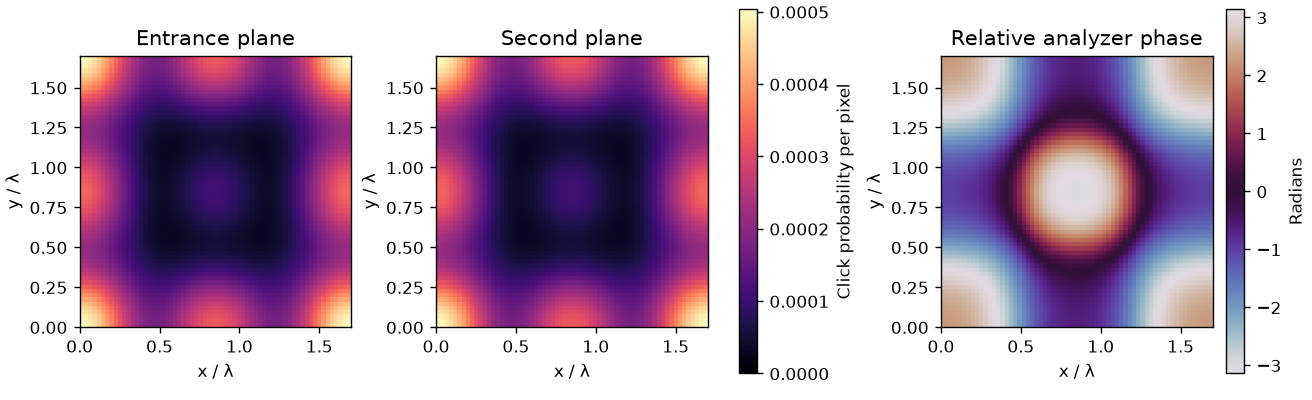

In [2]:
fig,axes=plt.subplots(1,3,figsize=(10.5,3.2),layout='constrained')
for ax,prob,title in zip(axes[:2],(p0,p1),('Entrance plane','Second plane')):
    im=ax.imshow(prob.T,extent=(0,d,0,d),origin='lower',cmap='magma',vmin=0,vmax=p0.max())
    ax.set(title=title,xlabel='x / λ',ylabel='y / λ')
fig.colorbar(im,ax=axes[:2],label='Click probability per pixel')
fixed_analyzer=analyzer*psi0
other_analyzer=analyzer*psi1
e=np.exp(2j*np.pi*np.outer(x/d,orders[:,0]))
f=np.exp(2j*np.pi*np.outer(x/d,orders[:,1]))
a0=(e*fixed_analyzer)@f.T
a1=(e*other_analyzer)@f.T
ph=np.angle(a1*a0.conj())
ph[abs(a1*a0)<1e-10]=np.nan
im2=axes[2].imshow(ph.T,extent=(0,d,0,d),origin='lower',cmap='twilight',vmin=-np.pi,vmax=np.pi)
axes[2].set(title='Relative analyzer phase',xlabel='x / λ',ylabel='y / λ')
fig.colorbar(im2,ax=axes[2],label='Radians')

## References
- R. J. Glauber, *The Quantum Theory of Optical Coherence*, Physical Review 130, 2529 (1963). https://doi.org/10.1103/PhysRev.130.2529
- B. J. Smith and M. G. Raymer, *Photon wave functions, wave-packet quantization of light, and coherence theory*, New Journal of Physics 9, 414 (2007). https://doi.org/10.1088/1367-2630/9/11/414
- W. D. Montgomery, *Self-imaging and unitarity*, Journal of the Optical Society of America 71, 1540–1541 (1981). https://doi.org/10.1364/JOSA.71.001540

In [ ]:
print("Saving the benchmark summary.")
try:
    from google.colab import drive
except ImportError:
    destination=Path('outputs/Quantum_Field_Diffraction')
else:
    drive.mount('/content/drive')
    destination=Path('/content/drive/MyDrive/Outputs/Quantum_Field_Diffraction')
destination.mkdir(parents=True,exist_ok=True)
file=destination/'quantum_click_self_imaging.json'
file.write_text(json.dumps(results,indent=2))
print(file)